# Chapitre 2 - Cours 2 : normalisation, jointures et relations plusieurs-à-plusieurs

Le cours 1 a montré le point fort du modèle document : un arbre de relations
un-à-plusieurs lu d'un seul bloc. Ce cours en montre la limite : dès que les
enregistrements **se référencent** entre eux, il faut des identifiants, des jointures, et
choisir entre données **normalisées** et **dénormalisées**. Il couvre les sections
*Many-to-One and Many-to-Many Relationships* et *Are Document Databases Repeating
History?* (*The network model*, *The relational model*, *Comparison to document
databases*).

**Plan.**

1. Un identifiant ou un texte ? La normalisation.
2. Le compromis lecture/écriture et la cohérence des copies.
3. Relations plusieurs-à-un et plusieurs-à-plusieurs.
4. Les bases documents répètent-elles l'histoire ? Modèles hiérarchique et réseau.

In [1]:
import json
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

orgs = dm.make_orgs(200, seed=0)
profiles = dm.make_profiles(20_000, seed=0, orgs=orgs)
con = sqlite3.connect(":memory:")
dm.create_relational(con, profiles, orgs)
dm.create_documents(con, profiles)

## 1. Un identifiant ou un texte ? La normalisation (section *Many-to-One and Many-to-Many Relationships*)

Dans nos profils, la région n'est pas stockée en clair (« Lyon, Auvergne-Rhône-Alpes,
France ») mais par un **identifiant** (`"fr:69"`) qui renvoie à une liste normalisée de
régions. Pourquoi ? Proposer une liste déroulante plutôt qu'un champ libre apporte :

- une **orthographe cohérente** d'un profil à l'autre ;
- l'absence d'**ambiguïté** entre lieux homonymes (Valence en France ou en Espagne ?) ;
- une **mise à jour facile** : le nom n'est stocké qu'à un endroit ;
- la **traduction** de l'interface : la liste se localise, pas les profils ;
- une **meilleure recherche** : la liste peut savoir que Lyon est dans le sud-est de la
  France, ce que la chaîne « Lyon » seule ne dit pas.

Stocker un identifiant, c'est **normaliser** : l'information lisible par un humain n'existe
qu'en un exemplaire, tout le reste y renvoie par un identifiant qui n'a de sens que dans
la base. Stocker le texte dans chaque enregistrement, c'est **dénormaliser** : on
duplique l'information. L'identifiant a un avantage décisif : n'ayant **aucun sens pour
un humain**, il n'a jamais besoin de changer, même quand ce qu'il désigne change.

Construisons les deux variantes de la table des profils et mesurons ce que coûte un
changement de nom de région (par exemple après une fusion de régions).

In [2]:
con.executescript("""
DROP TABLE IF EXISTS users_denorm;
CREATE TABLE users_denorm AS
  SELECT u.id, u.first_name, u.last_name, u.headline, r.name AS region_name
    FROM users u JOIN regions r ON r.id = u.region_id;
""")
taille = lambda t, cols: con.execute(f"SELECT SUM({' + '.join(f'LENGTH({c})' for c in cols)}) FROM {t}").fetchone()[0]
n_lyon = con.execute("SELECT COUNT(*) FROM users WHERE region_id = 'fr:69'").fetchone()[0]

def rename(normalise):
    t0 = time.perf_counter()
    if normalise:
        cur = con.execute("UPDATE regions SET name = 'Lyon, Région Lyonnaise, France' WHERE id = 'fr:69'")
    else:
        cur = con.execute("UPDATE users_denorm SET region_name = 'Lyon, Région Lyonnaise, France' "
                          "WHERE region_name = 'Lyon, Auvergne-Rhône-Alpes, France'")
    con.rollback()                                   # on annule pour garder les données intactes
    return cur.rowcount, (time.perf_counter() - t0) * 1e3

(n1, t1), (n2, t2) = rename(True), rename(False)
pd.DataFrame({
    "représentation": ["normalisée (region_id)", "dénormalisée (texte)"],
    "octets pour la région": [taille("users", ["region_id"]) + taille("regions", ["id", "name"]),
                              taille("users_denorm", ["region_name"])],
    "lignes modifiées par le renommage": [n1, n2],
    "temps (ms)": [t1, t2],
})

,représentation,octets pour la région,lignes modifiées par le renommage,temps (ms)
0,normalisée (region_id),102086,1,0.030
1,dénormalisée (texte),551644,1671,1.539


Le renommage touche **une ligne** dans la version normalisée, et les quelque
1 700 profils lyonnais dans la version dénormalisée, qui occupe aussi plusieurs fois plus de place.
Le prix de la normalisation se paie à la lecture : afficher un profil lisible demande
une **jointure** pour résoudre l'identifiant en texte.

In [3]:
SQL_JOIN = """SELECT users.first_name, users.last_name, regions.name
                FROM users JOIN regions ON users.region_id = regions.id
               WHERE users.id = ?"""
print(con.execute(SQL_JOIN, (251,)).fetchone())
for row in con.execute("EXPLAIN QUERY PLAN " + SQL_JOIN, (251,)):
    print("  plan :", row[-1])

('Yanis', 'Michel', 'Nantes, Pays de la Loire, France')
  plan : SEARCH users USING INTEGER PRIMARY KEY (rowid=?)
  plan : SEARCH regions USING INDEX sqlite_autoindex_regions_1 (id=?)


Les bases documents savent stocker des données normalisées ou non, mais on les associe
souvent à la dénormalisation : JSON rend facile l'ajout de champs redondants, et beaucoup
de bases documents gèrent mal les jointures. Sans jointure côté base, l'application la
fait elle-même : lire le document, puis lancer une seconde requête pour résoudre
l'identifiant. MongoDB propose aussi l'opérateur `$lookup` dans son pipeline
d'agrégation ; notre mini-moteur `dm.aggregate` l'implémente.

In [4]:
docs = [json.loads(r[0]) for r in con.execute("SELECT doc FROM profiles WHERE user_id IN (251, 252)")]
regions_coll = [{"_id": k, "name": v} for k, v in dm.REGIONS.items()]
res = dm.aggregate(docs, [
    {"$match": {"user_id": 251}},
    {"$lookup": {"from": "regions", "localField": "region_id", "foreignField": "_id", "as": "region"}},
    {"$project": {"_id": 0, "first_name": 1, "last_name": 1, "region": 1}},
], collections={"regions": regions_coll})
res

[{'first_name': 'Yanis',
  'last_name': 'Michel',
  'region': [{'_id': 'fr:44', 'name': 'Nantes, Pays de la Loire, France'}]}]

> **À retenir.** Normaliser, c'est ranger l'information lisible en un seul exemplaire et
> la référencer par un identifiant sans signification, qui n'a jamais à changer.
> Dénormaliser, c'est dupliquer le texte : lecture sans jointure, mais mises à jour
> multiples et risque d'incohérence.

## 2. Le compromis lecture/écriture et la cohérence des copies (section *Many-to-One and Many-to-Many Relationships*)

Dans nos CV, l'**organisation** d'un poste existe sous deux formes : son nom (texte
dénormalisé) et son identifiant `org_id` (normalisé). Supposons qu'on veuille afficher le
**logo** de chaque employeur. Dénormalisé, chaque poste porte l'URL du logo ; normalisé,
l'URL n'est stockée qu'une fois dans `organizations`.

Le coût d'un changement de logo dépend alors de la **popularité** de l'organisation. Or
les employeurs suivent une loi de Zipf : quelques géants, une longue traîne.

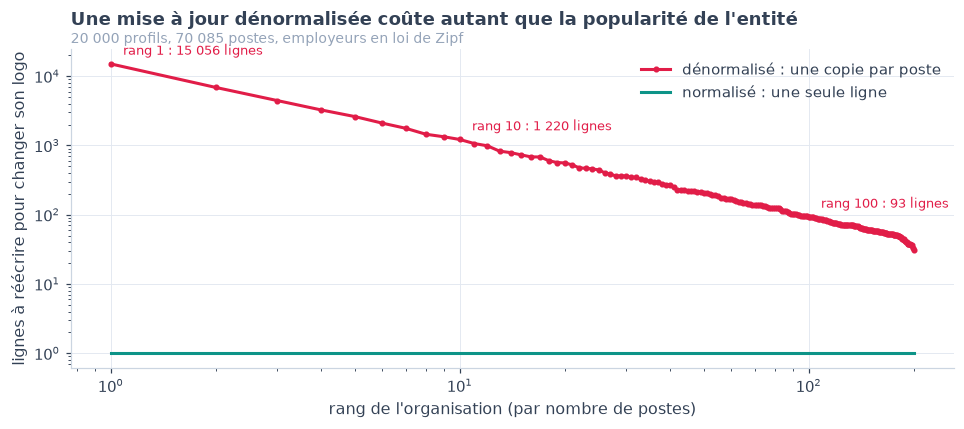

In [5]:
par_org = (pd.read_sql("SELECT org_id, COUNT(*) AS postes FROM positions GROUP BY org_id", con)
           .sort_values("postes", ascending=False).reset_index(drop=True))
par_org["rang"] = np.arange(1, len(par_org) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.loglog(par_org.rang, par_org.postes, marker="o", ms=3, color=ROSE, label="dénormalisé : une copie par poste")
ax.loglog(par_org.rang, np.ones(len(par_org)), color=TEAL, lw=2, label="normalisé : une seule ligne")
for r in [1, 10, 100]:
    v = par_org.postes[r - 1]
    ax.annotate(f"rang {r} : {fmt(v)} lignes", (r, v), (8, 6), textcoords="offset points", fontsize=8.5, color=ROSE)
ax.set_xlabel("rang de l'organisation (par nombre de postes)")
ax.set_ylabel("lignes à réécrire pour changer son logo")
ax.set_title("Une mise à jour dénormalisée coûte autant que la popularité de l'entité")
subtitle(ax, f"{fmt(len(profiles))} profils, {fmt(par_org.postes.sum())} postes, employeurs en loi de Zipf")
ax.legend(); plt.tight_layout(); plt.show()

Mesurons aussi l'autre côté du compromis, la **lecture** : afficher les postes d'un
profil avec le nom et le logo de l'employeur, avec ou sans jointure.

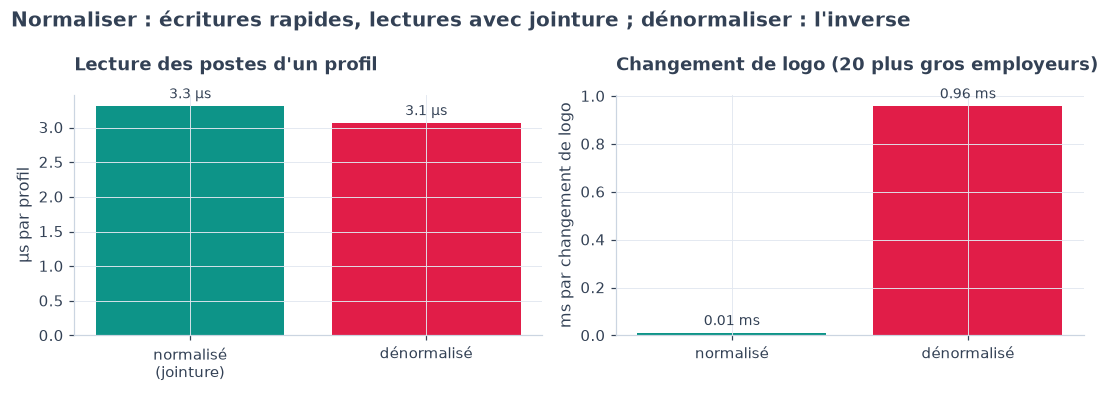

In [6]:
con.executescript("""
DROP TABLE IF EXISTS positions_denorm;
CREATE TABLE positions_denorm AS
  SELECT p.id, p.user_id, p.job_title, o.name AS org_name, o.logo_url, p.start, p."end"
    FROM positions p JOIN organizations o ON o.id = p.org_id;
CREATE INDEX pd_user ON positions_denorm (user_id);
CREATE INDEX pd_id ON positions_denorm (id);
CREATE INDEX pd_org ON positions_denorm (org_name);
""")
def bench(sql, n=3000):
    ids = rng.integers(1, len(profiles) + 1, n).tolist()
    t0 = time.perf_counter()
    for u in ids:
        con.execute(sql, (u,)).fetchall()
    return (time.perf_counter() - t0) / n * 1e6

lect_norm = bench("SELECT p.job_title, o.name, o.logo_url FROM positions p JOIN organizations o ON o.id = p.org_id WHERE p.user_id = ?")
lect_denorm = bench("SELECT job_title, org_name, logo_url FROM positions_denorm WHERE user_id = ?")
ecr = {}
for label, sql in [("normalisé", "UPDATE organizations SET logo_url = ? WHERE id = ?"),
                   ("dénormalisé", "UPDATE positions_denorm SET logo_url = ? WHERE org_name = (SELECT name FROM organizations WHERE id = ?)")]:
    t0 = time.perf_counter()
    for oid in par_org.org_id[:20]:
        con.execute(sql, ("/logos/v2.png", int(oid)))
    con.rollback()
    ecr[label] = (time.perf_counter() - t0) / 20 * 1e3

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(["normalisé\n(jointure)", "dénormalisé"], [lect_norm, lect_denorm], color=[TEAL, ROSE])
annotate_bars(axes[0], "{:.1f} µs"); axes[0].set_ylabel("µs par profil"); axes[0].set_title("Lecture des postes d'un profil")
axes[1].bar(["normalisé", "dénormalisé"], [ecr["normalisé"], ecr["dénormalisé"]], color=[TEAL, ROSE])
annotate_bars(axes[1], "{:.2f} ms"); axes[1].set_ylabel("ms par changement de logo")
axes[1].set_title("Changement de logo (20 plus gros employeurs)")
finish(fig, "Normaliser : écritures rapides, lectures avec jointure ; dénormaliser : l'inverse")

Sur une base locale, la lecture avec jointure n'est qu'à peine plus lente (une fraction
de microseconde par profil, car la table des organisations est petite et tient en
mémoire) ; la mise à jour dénormalisée, elle, est des centaines de fois plus lente, car
elle parcourt et réécrit toutes les copies. C'est le principe général énoncé par le
livre : des données normalisées sont **plus rapides à écrire** (une seule copie) et **plus
lentes à lire** (jointures) ; des données dénormalisées, l'inverse, avec en prime plus
d'espace disque.

**Et si le processus tombe en panne au milieu ?** Mettre à jour plusieurs copies, c'est
faire plusieurs écritures. Si le processus s'arrête entre deux, certaines copies portent
l'ancienne valeur, d'autres la nouvelle. Simulons un renommage de l'employeur le plus
populaire, interrompu à un instant aléatoire, avec et sans **transaction atomique**.

In [7]:
top = int(par_org.org_id[0])
top_name = con.execute("SELECT name FROM organizations WHERE id = ?", (top,)).fetchone()[0]
ids_top = [r[0] for r in con.execute("SELECT id FROM positions_denorm WHERE org_name = ?", (top_name,))]

def rename_with_crash(atomic, crash_after):
    """Renomme copie par copie ; une exception simule l'arrêt du processus."""
    try:
        if atomic:
            con.execute("BEGIN")
        for k, pid in enumerate(ids_top):
            if k == crash_after:
                raise RuntimeError("panne du processus")
            con.execute("UPDATE positions_denorm SET org_name = ? WHERE id = ?", (top_name + " SA", pid))
        con.commit()
    except RuntimeError:
        if atomic:
            con.rollback()                               # la base annule toute la transaction
        else:
            con.commit()                                 # sans transaction, le travail fait reste fait
    n_old = con.execute("SELECT COUNT(*) FROM positions_denorm WHERE org_name = ?", (top_name,)).fetchone()[0]
    n_new = con.execute("SELECT COUNT(*) FROM positions_denorm WHERE org_name = ?", (top_name + " SA",)).fetchone()[0]
    con.execute("UPDATE positions_denorm SET org_name = ? WHERE org_name = ?", (top_name, top_name + " SA"))
    con.commit()
    return n_old, n_new

con.isolation_level = None                               # contrôle explicite des transactions
crashes = sorted(rng.integers(1, len(ids_top), 8).tolist())
res = pd.DataFrame([(c, *rename_with_crash(False, c), *rename_with_crash(True, c)) for c in crashes],
                   columns=["panne après", "sans tx : ancien nom", "sans tx : nouveau nom",
                            "avec tx : ancien nom", "avec tx : nouveau nom"])
con.isolation_level = ""
res

,panne après,sans tx : ancien nom,sans tx : nouveau nom,avec tx : ancien nom,avec tx : nouveau nom
0,2476,12580,2476,15056,0
1,2614,12442,2614,15056,0
2,6937,8119,6937,15056,0
3,8069,6987,8069,15056,0
4,11969,3087,11969,15056,0
5,12385,2671,12385,15056,0
6,13377,1679,13377,15056,0
7,14548,508,14548,15056,0


Sans transaction, chaque panne laisse la base dans un état **mixte** : le même employeur
porte deux noms, et rien ne permet de savoir lequel est le bon. Avec une transaction
atomique, la base revient entièrement à l'état initial. C'est l'**atomicité** du chapitre
7 ; toutes les bases documents ne l'offrent pas pour une écriture qui
touche **plusieurs documents**.

**Quand normaliser ?** Le livre conseille la normalisation pour les systèmes
transactionnels, où lectures et écritures doivent être rapides, et pour les systèmes de
taille modeste, où le coût des jointures reste acceptable. Les systèmes analytiques, qui
écrivent par lots et lisent beaucoup, s'accommodent mieux de la dénormalisation. À très
grande échelle, le coût des jointures peut devenir un problème.

> **À retenir.** Normalisé : écriture en un point, lecture avec jointure. Dénormalisé :
> lecture directe, mais chaque mise à jour coûte autant que le nombre de copies (donc la
> popularité de l'entité) et une panne au milieu laisse des copies incohérentes, sauf
> transaction atomique.